# 5차시. 분류 모델 평가하기

In [1]:
from sklearn.datasets import load_breast_cancer         # 유방암 데이터셋
from sklearn.model_selection import train_test_split    # 데이터 분할
from sklearn.neighbors import KNeighborsClassifier      # KNN 분류 모델
from sklearn.metrics import confusion_matrix            # 혼동행렬 (숫자)
from sklearn.metrics import ConfusionMatrixDisplay      # 혼동행렬 (그림)
from sklearn.metrics import precision_score             # 정밀도
from sklearn.metrics import recall_score                # 재현율
from sklearn.metrics import f1_score                    # F1 점수
from sklearn.metrics import classification_report       # 지표 한 번에 보기

## 1. 학습목표
이번 차시에서 무엇을 할 수 있게 되는지 확인합니다.

## 2. 정확도의 함정
정확도가 높아도 쓸모없는 모델이 되는 경우를 살펴봅니다.

## 3. 양성과 음성
분류 평가에서 양성과 음성이 무엇을 뜻하는지 정리합니다.

## 4. 유방암 데이터 불러오기
유방암 데이터를 불러와 크기와 정답 숫자의 뜻을 확인합니다.

In [2]:
cancer = load_breast_cancer(as_frame=True)    # 유방암 데이터 불러오기
df = cancer.frame                             # 특성 + 정답 DataFrame
df.shape                                      # (행 수, 열 수)

(569, 31)

In [10]:
cancer.target_names
df = cancer.frame
df["target"].sum()

# 1을 환자로 만듦
df["target"] = 1 - df["target"]

X = df.drop(columns="target")
y = df["target"]
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

## 6. 분할 · 학습 · 정확도
데이터를 나누고 KNN을 학습시킨 뒤 테스트 정확도를 확인합니다.

In [12]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42 , stratify=y)

model = KNeighborsClassifier()
model.fit(X_train , y_train)
model.score(X_test , y_test)

0.9122807017543859

## 7. 혼동행렬 — confusion_matrix
실제 정답과 예측을 비교해 맞힌 경우와 틀린 경우를 네 칸으로 셉니다.

In [14]:
pred = model.predict(X_test)
confusion_matrix(y_test , pred)

array([[38,  4],
       [ 6, 66]])

## 8. 혼동행렬 시각화
혼동행렬을 색이 있는 그림으로 그려 한눈에 봅니다.

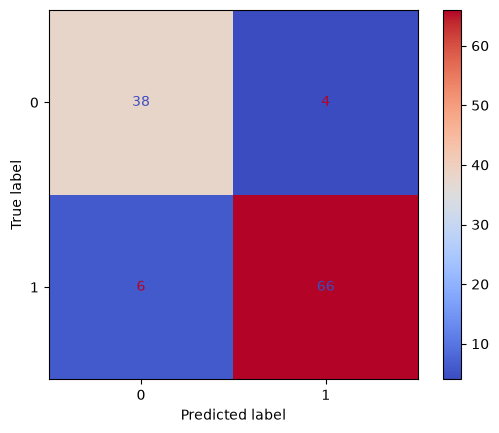

In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, pred , cmap="coolwarm")

## 9. 정밀도와 재현율
악성을 기준으로 정밀도와 재현율을 계산합니다.

In [17]:
# 정밀도
precision = precision_score(y_test , pred)

#재현율
recall = recall_score(y_test , pred)
recall

0.9166666666666666

## 10. 어떤 지표가 중요할까 — F1
상황에 따라 중요한 지표가 다름을 이해하고 F1 점수를 계산합니다.

In [18]:
f1_score(y_test , pred)

0.9295774647887324

## 11. 한 번에 보기 — classification_report
정밀도, 재현율, F1을 표 하나로 출력합니다.

In [19]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88        42
           1       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114



## 12. 종합 실습 — k를 바꿔 비교
k=15 모델의 혼동행렬과 재현율을 구해 k=5 모델과 비교합니다.

In [23]:
model_15 = KNeighborsClassifier(n_neighbors=15)
model_15.fit(X_train , y_train)
pred_15 = model_15.predict(X_test)

confusion_matrix(y_test , pred_15)

print(classification_report(y_test , pred_15))

              precision    recall  f1-score   support

           0       0.98      0.65      0.78       170
           1       0.83      0.99      0.90       286

    accuracy                           0.87       456
   macro avg       0.91      0.82      0.84       456
weighted avg       0.89      0.87      0.86       456

